# Optional Lab: Feature Engineering and Polynomial Regression

# 特征工程与多项式回归

![](./images/C1_W2_Lab07_FeatureEngLecture.PNG)


## Goals（目标）

在本实验中，您将：

- 探索特征工程和多项式回归，这允许您使用线性回归的机制来拟合非常复杂，甚至是非线性的函数。


In this lab you will:
- explore feature engineering and polynomial regression which allows you to use the machinery of linear regression to fit very complicated, even very non-linear functions.


## Tools
You will utilize the function developed in previous labs as well as matplotlib and NumPy. 

## 参考资料

https://zh.wikipedia.org/wiki/%E5%A4%9A%E9%A0%85%E5%BC%8F 多项式的定义

https://aibydoing.com/notebooks/chapter01-04-lab-polynomial-regression-implementation-and-applications
    
https://www.cnblogs.com/dataanaly/p/12937068.html

线性回归只能处理线性数据，就是使用多项式回归对线性回归进行改进

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from lab_utils_multi import zscore_normalize_features, run_gradient_descent_feng
np.set_printoptions(precision=2,suppress = True)  # reduced display precision on numpy arrays

<a name='FeatureEng'></a>
# Feature Engineering and Polynomial Regression Overview

# 特征工程和多项式回归概述


Out of the box, linear regression provides a means of building models of the form:

线性回归本身提供了一种构建模型的方法，其形式为：

$$f_{\mathbf{w},b} = w_0x_0 + w_1x_1+ ... + w_{n-1}x_{n-1} + b \tag{1}$$ 


但如果你的特征/数据是非线性的，或者是特征的组合怎么办？ 例如，房价与居住面积的关系往往不是线性的，而是会惩罚非常小或非常大的房子，导致出现上图中所示的曲线。那么我们如何使用线性回归的机制来拟合这种曲线呢？回想一下，我们拥有的“机制”是能够修改公示（1）中的参数$\mathbf{w}$，$\mathbf{b}$，以“拟合”方程到训练数据上。然而，无论我们如何调整公示（1）中的$\mathbf{w}$，$\mathbf{b}$，都无法实现对非线性曲线的拟合。


What if your features/data are non-linear or are combinations of features? For example,  Housing prices do not tend to be linear with living area but penalize very small or very large houses resulting in the curves shown in the graphic above. How can we use the machinery of linear regression to fit this curve? Recall, the 'machinery' we have is the ability to modify the parameters $\mathbf{w}$, $\mathbf{b}$ in (1) to 'fit' the equation to the training data. However, no amount of adjusting of $\mathbf{w}$,$\mathbf{b}$ in (1) will achieve a fit to a non-linear curve.


<a name='PolynomialFeatures'></a>
## Polynomial Features（多项式特征）

在上面的讨论中，我们考虑了一个数据是非线性的场景。现在，我们将尝试使用到目前为止所学的知识来拟合一个非线性曲线。我们将从一个简单的二次方程开始： $y = 1+x^2$

Above we were considering a scenario where the data was non-linear. Let's try using what we know so far to fit a non-linear curve. We'll start with a simple quadratic: $y = 1+x^2$


你已经熟悉了我们将要使用的所有程序。这些程序可以在lab_utils.py文件中找到以供复习。我们将使用[`np.c_[..]`](https://numpy.org/doc/stable/reference/generated/numpy.c_.html)，这是NumPy中的一个函数，用于沿着列边界进行拼接（concatenate）。

You're familiar with all the routines we're using. They are available in the lab_utils.py file for review. We'll use [`np.c_[..]`](https://numpy.org/doc/stable/reference/generated/numpy.c_.html) which is a NumPy routine to concatenate along the column boundary.

In [5]:
print(np.array([1,2,3]).shape)
print(np.array([4,5,6]).shape)
print(np.c_[np.array([1,2,3]), np.array([4,5,6])].shape)#Translates slice objects to concatenation along the second axis.
#np.c_[np.array([[1,2,3]]), 0, 0, np.array([[4,5,6]])]

(3,)
(3,)
(3, 2)


In [6]:
np.concatenate((np.array([1,2,3]).reshape(3,1),np.array([4,5,6]).reshape(3,1)), axis=1)

array([[1, 4],
       [2, 5],
       [3, 6]])

In [7]:
np.array([[1, 2], [3, 4]]).shape

(2, 2)

Iteration         0, Cost: 1.65756e+03
Iteration       100, Cost: 6.94549e+02
Iteration       200, Cost: 5.88475e+02
Iteration       300, Cost: 5.26414e+02
Iteration       400, Cost: 4.90103e+02
Iteration       500, Cost: 4.68858e+02
Iteration       600, Cost: 4.56428e+02
Iteration       700, Cost: 4.49155e+02
Iteration       800, Cost: 4.44900e+02
Iteration       900, Cost: 4.42411e+02
w,b found by gradient descent: w: [18.7], b: -52.0834


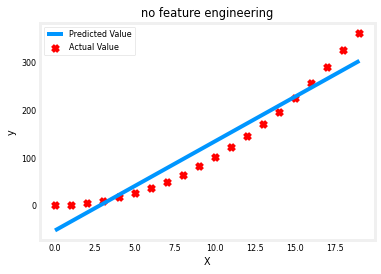

In [8]:
# create target data
x = np.arange(0, 20, 1)
y = 1 + x**2
X = x.reshape(-1, 1)

model_w,model_b = run_gradient_descent_feng(X,y,iterations=1000, alpha = 1e-2)

plt.scatter(x, y, marker='x', c='r', label="Actual Value"); plt.title("no feature engineering")
plt.plot(x,X@model_w + model_b, label="Predicted Value");  plt.xlabel("X"); plt.ylabel("y"); plt.legend(); plt.show()
#使用 @ 来执行矩阵乘法

In [9]:
X.shape

(20, 1)

In [10]:
model_w.shape

(1,)

正如所料，这并不是一个很好的拟合。我们需要的是类似 $y= w_0x_0^2 + b$ 的形式，或者称为**多项式特征**。为了实现这一点，你可以修改输入数据来构造所需的特征。如果你将原始数据替换为 $x$ 值的平方版本，那么你就可以实现 $y= w_0x_0^2 + b$。让我们试试看。将下面的 `X` 替换为 `X**2`：


Well, as expected, not a great fit. What is needed is something like $y= w_0x_0^2 + b$, or a **polynomial feature**.
To accomplish this, you can modify the *input data* to *engineer* the needed features. If you swap the original data with a version that squares the $x$ value, then you can achieve $y= w_0x_0^2 + b$. Let's try it. Swap `X` for `X**2` below:

In [11]:
# create target data
x = np.arange(0, 20, 1)
y = 1 + x**2

# Engineer features 
X = x**2      #<-- added engineered feature

Iteration         0, Cost: 7.32922e+03
Iteration      1000, Cost: 2.24844e-01
Iteration      2000, Cost: 2.22795e-01
Iteration      3000, Cost: 2.20764e-01
Iteration      4000, Cost: 2.18752e-01
Iteration      5000, Cost: 2.16758e-01
Iteration      6000, Cost: 2.14782e-01
Iteration      7000, Cost: 2.12824e-01
Iteration      8000, Cost: 2.10884e-01
Iteration      9000, Cost: 2.08962e-01
w,b found by gradient descent: w: [1.], b: 0.0490


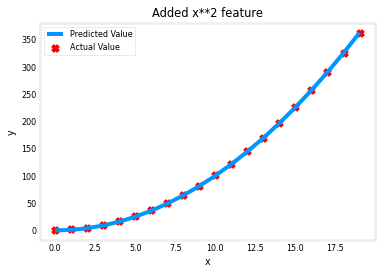

In [12]:
X = X.reshape(-1, 1)  #X should be a 2-D Matrix
model_w,model_b = run_gradient_descent_feng(X, y, iterations=10000, alpha = 1e-5)

plt.scatter(x, y, marker='x', c='r', label="Actual Value"); plt.title("Added x**2 feature")
plt.plot(x, np.dot(X,model_w) + model_b, label="Predicted Value"); plt.xlabel("x"); plt.ylabel("y"); plt.legend(); plt.show()

非常好！接近完美的拟合。请注意在图表上方打印的 $\mathbf{w}$ 和 b 的值：`gradient descent找到的w,b: w: [1.], b: 0.0490`。梯度下降算法修改了我们的初始 $\mathbf{w},b $  值为 (1.0, 0.049)，或者模型为 $y=1*x_0^2+0.049$， 这非常接近我们的目标 $y=1*x_0^2+1$。如果你运行更长的时间，它可能会更加匹配。

Great! near perfect fit. Notice the values of $\mathbf{w}$ and b printed right above the graph: `w,b found by gradient descent: w: [1.], b: 0.0490`. Gradient descent modified our initial values of $\mathbf{w},b $ to be (1.0,0.049) or a model of $y=1*x_0^2+0.049$, very close to our target of $y=1*x_0^2+1$. If you ran it longer, it could be a better match. 

### Selecting Features（选择特征）
<a name='GDF'></a>

在上面，我们知道需要一个$x^2$ 项。但并不一定总是很明显需要哪些特征。我们可以添加各种潜在的特征来尝试并找到最有用的特征。例如，如果我们尝试：$y=w_0x_0 + w_1x_1^2 + w_2x_2^3+b$ 会怎么样呢？

运行下面的代码块。


Above, we knew that an $x^2$ term was required. It may not always be obvious which features are required. One could add a variety of potential features to try and find the most useful. For example, what if we had instead tried : $y=w_0x_0 + w_1x_1^2 + w_2x_2^3+b$ ? 

Run the next cells. 

In [13]:
# create target data
x = np.arange(0, 20, 1)
y = x**2
# engineer features .
X = np.c_[x, x**2, x**3]   #<-- added engineered feature   

In [14]:
x

array([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15, 16,
       17, 18, 19])

In [15]:
X

array([[   0,    0,    0],
       [   1,    1,    1],
       [   2,    4,    8],
       [   3,    9,   27],
       [   4,   16,   64],
       [   5,   25,  125],
       [   6,   36,  216],
       [   7,   49,  343],
       [   8,   64,  512],
       [   9,   81,  729],
       [  10,  100, 1000],
       [  11,  121, 1331],
       [  12,  144, 1728],
       [  13,  169, 2197],
       [  14,  196, 2744],
       [  15,  225, 3375],
       [  16,  256, 4096],
       [  17,  289, 4913],
       [  18,  324, 5832],
       [  19,  361, 6859]])

Iteration         0, Cost: 1.14029e+03
Iteration      1000, Cost: 3.28539e+02
Iteration      2000, Cost: 2.80443e+02
Iteration      3000, Cost: 2.39389e+02
Iteration      4000, Cost: 2.04344e+02
Iteration      5000, Cost: 1.74430e+02
Iteration      6000, Cost: 1.48896e+02
Iteration      7000, Cost: 1.27100e+02
Iteration      8000, Cost: 1.08495e+02
Iteration      9000, Cost: 9.26132e+01
w,b found by gradient descent: w: [0.08 0.54 0.03], b: 0.0106


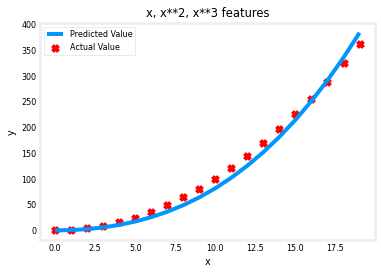

In [16]:
model_w,model_b = run_gradient_descent_feng(X, y, iterations=10000, alpha=1e-7)

plt.scatter(x, y, marker='x', c='r', label="Actual Value"); plt.title("x, x**2, x**3 features")
plt.plot(x, X@model_w + model_b, label="Predicted Value"); plt.xlabel("x"); plt.ylabel("y"); plt.legend(); plt.show()

请注意 $\mathbf{w}$ 的值，`[0.08 0.54 0.03]` 和 b 的值是 `0.0106`。这意味着拟合/训练后的模型为：

$$ 0.08x + 0.54x^2 + 0.03x^3 + 0.0106 $$

相对于其他项,梯度下降算法通过增加 $w_1$ 项的值，强调了与 $x^2$ 数据最匹配的数据。如果你运行很长时间，它将继续减少其他项的影响。

Note the value of $\mathbf{w}$, `[0.08 0.54 0.03]` and b is `0.0106`.This implies the model after fitting/training is:
$$ 0.08x + 0.54x^2 + 0.03x^3 + 0.0106 $$
Gradient descent has emphasized the data that is the best fit to the $x^2$ data by increasing the $w_1$ term relative to the others.  If you were to run for a very long time, it would continue to reduce the impact of the other terms. 

>梯度下降算法通过强调其相关参数来为我们选择“正确”的特征

>Gradient descent is picking the 'correct' features for us by emphasizing its associated parameter


让我们回顾一下这个概念:
- 最初，特征被重新缩放，以便它们之间可以相互比较。
- 较小的权重值意味着不太重要/正确的特征，而在极端情况下，当权重变为零或非常接近零时，与该权重相关的特征在将数据拟合到模型时不再有用。
- 在上面的例子中，拟合后，与 $x^2$ 特征相关联的权重远大于 $x$ 或 $x^3$ 的权重，这是因为$x^2$在拟合数据时最为有用。

Let's review this idea:
- Intially, the features were re-scaled so they are comparable to each other
- less weight value implies less important/correct feature, and in extreme, when the weight becomes zero or very close to zero, the associated feature useful in fitting the model to the data.
- above, after fitting, the weight associated with the $x^2$ feature is much larger than the weights for $x$ or $x^3$ as it is the most useful in fitting the data. 

### An Alternate View（另一种观点）

上面，多项式特征的选择基于它们与目标数据的匹配程度。另一种思考方式是，一旦我们创建了新的特征，我们仍然在使用线性回归。鉴于这一点，最佳特征将相对于目标而言是线性的。这通过例子来理解最为直观。

Above, polynomial features were chosen based on how well they matched the target data. Another way to think about this is to note that we are still using linear regression once we have created new features. Given that, the best features will be linear relative to the target. This is best understood with an example. 

In [17]:
# create target data
x = np.arange(0, 20, 1)
y = x**2

# engineer features .
X = np.c_[x, x**2, x**3]   #<-- added engineered feature
X_features = ['x','x^2','x^3']

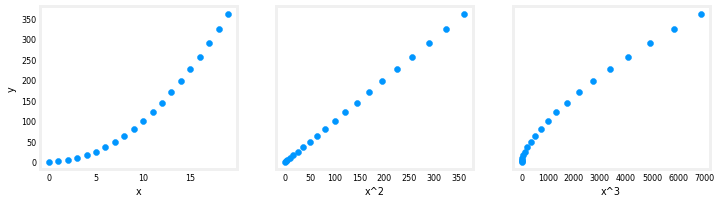

In [18]:
fig,ax=plt.subplots(1, 3, figsize=(12, 3), sharey=True)
for i in range(len(ax)):
    ax[i].scatter(X[:,i],y)
    ax[i].set_xlabel(X_features[i])
ax[0].set_ylabel("y")
plt.show()

在上面，很明显 $x^2$ 特征与目标值 $y$ 之间的映射是线性的。因此，线性回归可以很容易地利用这个特征生成一个模型。

Above, it is clear that the $x^2$ feature mapped against the target value $y$ is linear. Linear regression can then easily generate a model using that feature.

### Scaling features（特征缩放）

正如在上一实验中描述的，如果数据集的特征具有显著不同的尺度，那么应该应用特征缩放来加速梯度下降。在上面的例子中，有 $x$、$x^2$和 $x^3$，它们的尺度自然会非常不同。让我们对我们的例子应用Z-score标准化。 

As described in the last lab, if the data set has features with significantly different scales, one should apply feature scaling to speed gradient descent. In the example above, there is $x$, $x^2$ and $x^3$ which will naturally have very different scales. Let's apply Z-score normalization to our example.

In [19]:
# create target data
x = np.arange(0,20,1)
X = np.c_[x, x**2, x**3]
print(f"Peak to Peak range by column in Raw        X:{np.ptp(X,axis=0)}")

# add mean_normalization 
X = zscore_normalize_features(X)     
print(f"Peak to Peak range by column in Normalized X:{np.ptp(X,axis=0)}")

Peak to Peak range by column in Raw        X:[  19  361 6859]
Peak to Peak range by column in Normalized X:[3.3  3.18 3.28]


现在我们可以尝试一个更激进的alpha值：

Now we can try again with a more aggressive value of alpha:

Iteration         0, Cost: 9.42147e+03
Iteration     10000, Cost: 3.90938e-01
Iteration     20000, Cost: 2.78389e-02
Iteration     30000, Cost: 1.98242e-03
Iteration     40000, Cost: 1.41169e-04
Iteration     50000, Cost: 1.00527e-05
Iteration     60000, Cost: 7.15855e-07
Iteration     70000, Cost: 5.09763e-08
Iteration     80000, Cost: 3.63004e-09
Iteration     90000, Cost: 2.58497e-10
w,b found by gradient descent: w: [  0.   113.49   0.  ], b: 123.5000


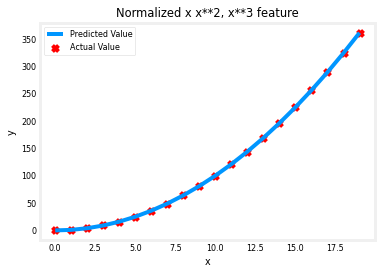

In [20]:
x = np.arange(0,20,1)
y = x**2

X = np.c_[x, x**2, x**3]
X = zscore_normalize_features(X) 

model_w, model_b = run_gradient_descent_feng(X, y, iterations=100000, alpha=1e-1)

plt.scatter(x, y, marker='x', c='r', label="Actual Value"); plt.title("Normalized x x**2, x**3 feature")
plt.plot(x,X@model_w + model_b, label="Predicted Value"); plt.xlabel("x"); plt.ylabel("y"); plt.legend(); plt.show()

特征缩放允许它更快地收敛。

再次注意 $\mathbf{w}$ 的值。 $w_1$ 项，即给给予较大权重的$x^2$项，。梯度下降几乎完全消除了 $x^3$ 项。


Feature scaling allows this to converge much faster.   
Note again the values of $\mathbf{w}$. The $w_1$ term, which is the $x^2$ term is the most emphasized. Gradient descent has all but eliminated the $x^3$ term.

### Complex Functions（复杂函数）

通过特征工程，即使是相当复杂的函数也可以被建模：

With feature engineering, even quite complex functions can be modeled:

In [ ]:
x = np.arange(0,20,1)
y = np.cos(x/2)

X = np.c_[x, x**2, x**3,x**4, x**5, x**6, x**7, x**8, x**9, x**10, x**11, x**12, x**13]
X = zscore_normalize_features(X) 

model_w,model_b = run_gradient_descent_feng(X, y, iterations=1000000, alpha = 1e-1)

plt.scatter(x, y, marker='x', c='r', label="Actual Value"); plt.title("Normalized x x**2, x**3 feature")
plt.plot(x,X@model_w + model_b, label="Predicted Value"); plt.xlabel("x"); plt.ylabel("y"); plt.legend(); plt.show()



## Congratulations!
In this lab you:
- learned how linear regression can model complex, even highly non-linear functions using feature engineering
- recognized that it is important to apply feature scaling when doing feature engineering

##  恭喜！
在这个实验中，你：

- 学习了如何使用特征工程使线性回归能够模拟复杂甚至高度非线性的函数
- 认识到在进行特征工程时应用特征缩放的重要性